In [1]:
import pandas as pd
import numpy as np
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn import tree
from sklearn.model_selection import train_test_split
from tools import proccess_data
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt


In [31]:
# Own created feature engineering

data_name = '100K_accts_EASY25'

edge_path = '../flib/AMLsim/outputs/'+data_name+'/tx_log.csv'
node_path = '../flib/AMLsim/outputs/'+data_name+'/node_log.csv'
 
edge_data = pd.read_csv(edge_path)
node_data = pd.read_csv(node_path)

print('Data is loaded')

features, labels, true_labels = proccess_data(edge_data, node_data)


features = features.drop(['node_id'], axis=1)
labels = labels.drop(['node_id'], axis=1)
true_labels = true_labels.drop(['node_id'], axis=1)

print(features.head())

# Normalize the features
scaler = StandardScaler()
features = scaler.fit_transform(features)

print('Data is preprocessed')

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=2) #
_, _, y_train_true, y_test_true = train_test_split(features, true_labels, test_size=0.2, random_state=2)

print('Data is split')


Data is loaded
   avg_amount_sent  total_amount_sent  total_transactions_sent  \
0          1445.72          315166.14                      218   
1           854.10          183631.08                      215   
2          1442.24          324504.97                      225   
3          1442.71          314510.85                      218   
4           917.57          175255.06                      191   

   avg_amount_rec  total_amount_rec  total_transactions_rec  \
0         9972.74         478691.50                      48   
1         4719.21         240679.82                      51   
2         6631.31         344828.00                      52   
3         8102.81         429448.96                      53   
4         3141.81         169657.99                      54   

   avg_phone_changes  total_phone_changes  INIT_BALANCE  BANK_ID  \
0                0.0                    0      63986.15        0   
1                0.0                    0      13712.27        0   
2    

In [2]:
# GNN preprocessing

data_name = '100K_accts_HARD1'

data_path = '~/flib/gnn/data/'+data_name+'/nodes.csv'
 
data = pd.read_csv(data_path)

print('Data is loaded')


features = data.drop(['is_sar','account'], axis=1)
labels = data[['is_sar']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=2) #

# Normalize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


print('Data is preprocessed')


Data is loaded
Data is preprocessed


In [3]:
from imblearn.over_sampling import RandomOverSampler

y_train = np.ravel(y_train)
y_test = np.ravel(y_test)

ros = RandomOverSampler(sampling_strategy=0.7)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

sample_weight = np.ones(y_train_ros.shape[0])
sample_weight[y_train_ros==1] = 15 # 25

In [4]:
svm_sample_weight = np.ones(y_train.shape[0])
svm_sample_weight[y_train==1] = 15 # 25

svm_model = svm.SVC(kernel='rbf')
svm_model.fit(X_train, y_train, sample_weight=svm_sample_weight)

print('Model is trained')


Model is trained


In [5]:
# knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model = KNeighborsClassifier(metric= 'euclidean', n_neighbors= 43, weights= 'distance') # AP Grid search

knn_model.fit(X_train_ros, y_train_ros)



print('Model is trained')

Model is trained


In [6]:
# log_model = LogisticRegression(class_weight='balanced', max_iter=1000)
log_model = LogisticRegression(C= 10, max_iter= 1000, penalty= 'l1', solver= 'liblinear') # AP Grid Search
log_model.fit(X_train_ros, y_train_ros,sample_weight=sample_weight)

print('Model is trained')

Model is trained


In [7]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(n_estimators=100, max_depth=21, min_samples_leaf=11, min_samples_split=9) 

random_forest_model.fit(X_train_ros,y_train_ros,sample_weight)

print('Model is trained')

Model is trained


In [8]:
from sklearn.ensemble import GradientBoostingClassifier

xgboost_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=5,min_samples_leaf=5, min_samples_split=5)
xgboost_model.fit(X_train_ros, y_train_ros, sample_weight)

print('Model is trained')

Model is trained


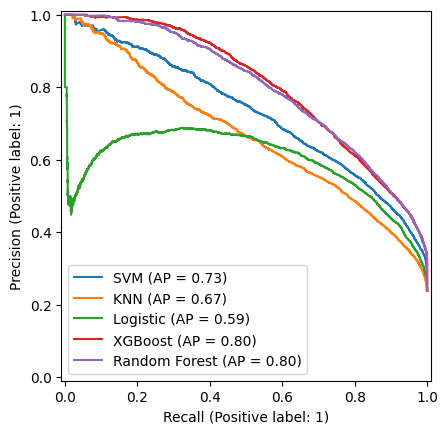

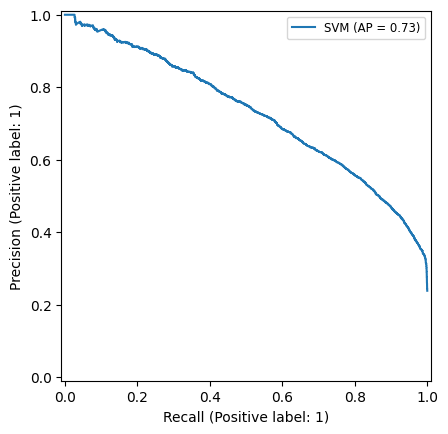

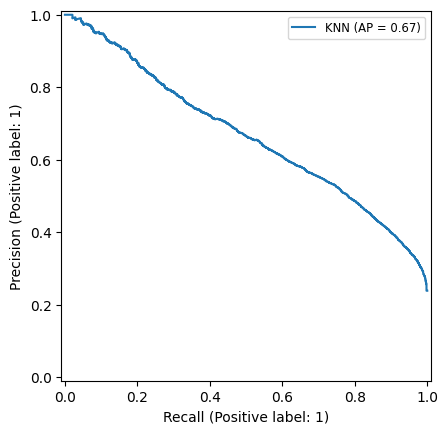

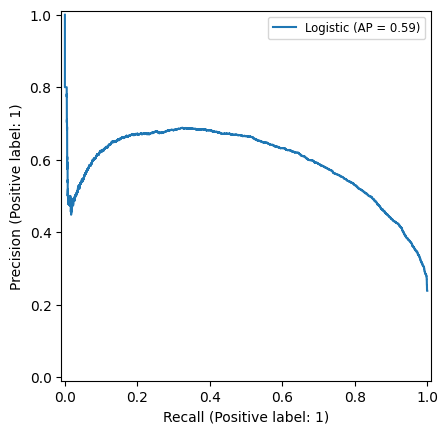

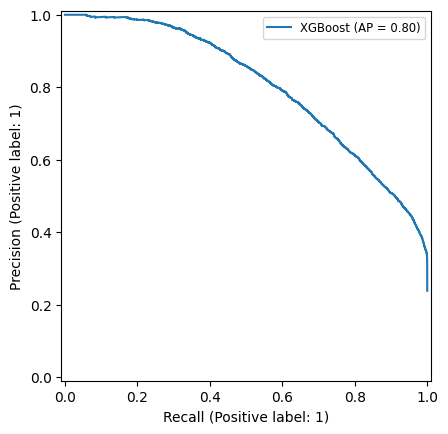

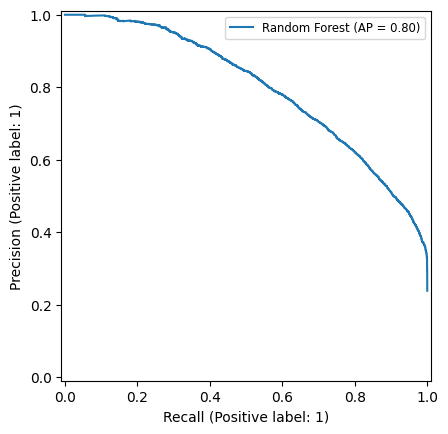

In [9]:
from sklearn.metrics import PrecisionRecallDisplay

# display = PrecisionRecallDisplay.from_estimator(svm_model, X_test, y_test, name='SVM')
# display.plot()

# In the same plot, plot all the different models precision-recall curves, using the models not the predictions
names = ['SVM', 'KNN', 'Logistic','XGBoost','Random Forest']
models = [svm_model, knn_model, log_model, xgboost_model, random_forest_model]
fig, ax = plt.subplots()
for i, model in enumerate(models):
    display = PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=names[i])
    display.plot(ax=ax)
    # make legend smaller
    plt.legend(fontsize='small')
plt.show()

In [10]:
# Print the important features
model = random_forest_model
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
print("Feature ranking:")
for f in range(X_train.shape[1]):
    print("%d. feature %d (%f)" % (f + 1, indices[f], importances[indices[f]]))

Feature ranking:
1. feature 8 (0.200595)
2. feature 9 (0.189451)
3. feature 4 (0.077527)
4. feature 5 (0.072415)
5. feature 6 (0.060538)
6. feature 3 (0.052333)
7. feature 7 (0.049329)
8. feature 0 (0.038082)
9. feature 1 (0.034316)
10. feature 2 (0.030252)
11. feature 13 (0.027731)
12. feature 15 (0.027365)
13. feature 12 (0.026490)
14. feature 16 (0.025574)
15. feature 14 (0.024481)
16. feature 18 (0.022170)
17. feature 17 (0.022003)
18. feature 10 (0.019268)
19. feature 11 (0.000079)


In [11]:
# From precision and recall calculate the AUC

from sklearn.metrics import auc

auc_score = auc(recall, precision)
print('AUC: ', auc_score)

NameError: name 'recall' is not defined

In [ ]:
# Calculate AUC
from sklearn.metrics import auc
from sklearn.metrics import precision_recall_curve

for i, model in enumerate([svm_model, tree_model, QDA_model, knn_model, log_model]):
    y_pred = model.decision_function(X_test)
    precision, recall, _ = precision_recall_curve(y_test, y_pred)
    auc_score = auc(recall, precision)
    print('AUC: ', names[i], auc_score)

AUC:  SVM 0.7185510507880507


AttributeError: 'DecisionTreeClassifier' object has no attribute 'decision_function'

In [ ]:
# Print count of each class

print('Labels count: ')
print(np.unique(labels, return_counts=True))


Labels count: 
(array([0, 1]), array([95730,  4270]))


In [ ]:
print(round(labels[labels == 1].shape[0]/labels[labels==0].shape[0],3))

0.045


In [ ]:
# Confusion matrix
from sklearn.metrics import confusion_matrix
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix)

# Display the confusion matrix 

# import seaborn as sns
# import matplotlib.pyplot as plt

# sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')

[[19126    61]
 [  305   508]]
